In [13]:


import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans


data = pd.DataFrame({
    'CustomerID': ['C1','C2','C3','C4','C5','C6',
                   'C7','C8','C9','C10','C11','C12'],
    'Annual_Income': [1,1.5,2,2,7,7.5,8,8,4,4.5,5,5],
    'Spending_Score': [1,2,1.5,2.5,1,2,1.5,2.5,7,8,7.5,8.5]
})

print("CUSTOMER DATASET")
print(data)



CUSTOMER DATASET
   CustomerID  Annual_Income  Spending_Score
0          C1            1.0             1.0
1          C2            1.5             2.0
2          C3            2.0             1.5
3          C4            2.0             2.5
4          C5            7.0             1.0
5          C6            7.5             2.0
6          C7            8.0             1.5
7          C8            8.0             2.5
8          C9            4.0             7.0
9         C10            4.5             8.0
10        C11            5.0             7.5
11        C12            5.0             8.5


C:\Users\User\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1425: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\User\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1425: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\User\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1425: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\User\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1425: UserWarning: KMeans is known to have a memory leak on Windows wi

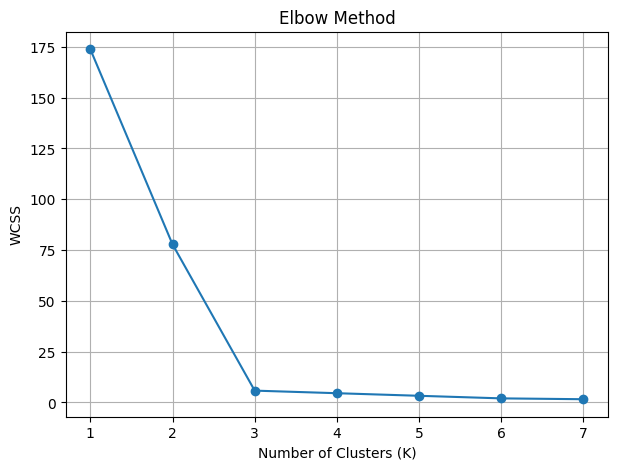

In [15]:

X = data[['Annual_Income', 'Spending_Score']]

wcss = []

for k in range(1, 8):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X)
    wcss.append(model.inertia_)

plt.figure(figsize=(7,5))
plt.plot(range(1,8), wcss, marker='o')
plt.title('Elbow Method')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('WCSS')
plt.xticks(range(1,8))
plt.grid(True)
plt.show()


In [17]:

kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
data['Cluster'] = kmeans.fit_predict(X)


print("\nCUSTOMER CLUSTER ASSIGNMENTS")
print(data)


print("\nCLUSTER CENTROIDS")
print(kmeans.cluster_centers_)


CUSTOMER CLUSTER ASSIGNMENTS
   CustomerID  Annual_Income  Spending_Score  Cluster
0          C1            1.0             1.0        2
1          C2            1.5             2.0        2
2          C3            2.0             1.5        2
3          C4            2.0             2.5        2
4          C5            7.0             1.0        0
5          C6            7.5             2.0        0
6          C7            8.0             1.5        0
7          C8            8.0             2.5        0
8          C9            4.0             7.0        1
9         C10            4.5             8.0        1
10        C11            5.0             7.5        1
11        C12            5.0             8.5        1

CLUSTER CENTROIDS
[[7.625 1.75 ]
 [4.625 7.75 ]
 [1.625 1.75 ]]


C:\Users\User\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1425: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


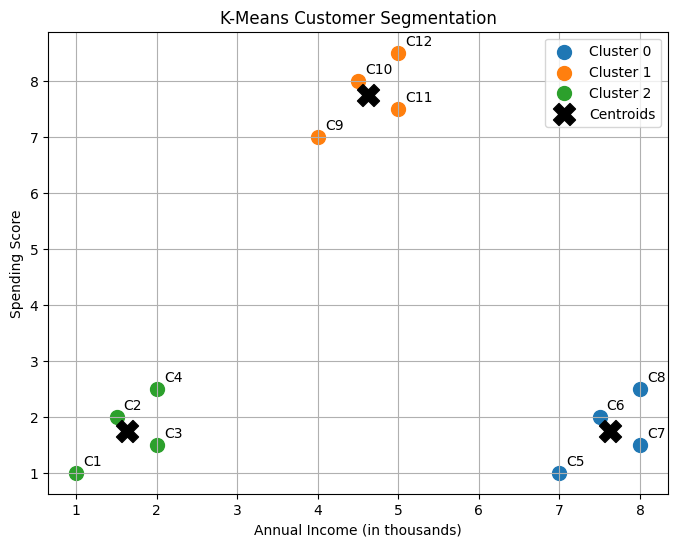

In [19]:

plt.figure(figsize=(8,6))

for cluster in sorted(data['Cluster'].unique()):
    cluster_data = data[data['Cluster'] == cluster]
    plt.scatter(
        cluster_data['Annual_Income'],
        cluster_data['Spending_Score'],
        s=100,
        label=f'Cluster {cluster}'
    )


plt.scatter(
    kmeans.cluster_centers_[:,0],
    kmeans.cluster_centers_[:,1],
    s=250,
    marker='X',
    color='black',
    label='Centroids'
)


for i in range(len(data)):
    plt.annotate(
        data['CustomerID'][i],
        (data['Annual_Income'][i],
         data['Spending_Score'][i]),
        xytext=(5,5),
        textcoords='offset points'
    )

plt.title('K-Means Customer Segmentation')
plt.xlabel('Annual Income (in thousands)')
plt.ylabel('Spending Score')
plt.legend()
plt.grid(True)
plt.show()

In [21]:

print("\nCLUSTER SUMMARY")
print(data.groupby('Cluster')[
    ['Annual_Income','Spending_Score']
].mean())


CLUSTER SUMMARY
         Annual_Income  Spending_Score
Cluster                               
0                7.625            1.75
1                4.625            7.75
2                1.625            1.75
